# P1.02 — Affordability indicators: trends and maps

**Questions:** RQ1.4 (affordability relative to income), RQ1.5 (years of income to buy a typical home),
RQ1.7 (mortgage rates and lending conditions), RQ4.2 (where affordability deteriorated most).

Indicators are defined in `docs/methodology.md`:
* **PTI** — price-to-income: years of median income to buy a home of the municipality's average size;
* **RTI** — rent-to-income: a year of rent on that home as a share of median income (2020–2024);
* **mortgage burden** — yearly payments on an 80% loan over 30 years at the market rate, as a share of income.

Income is the median per IRS tax household, which includes single filers, so **levels are high and not
comparable with international figures**: read rankings and changes.

In [1]:
from pthousing.analysis import descriptive as desc
from pthousing.data import build_panel
from pthousing.viz import charts, maps, style

style.apply_style()
panel = build_panel.read("panel_municipality_year")
y24 = panel[panel["year"] == 2024].set_index("muni_code")
geometry = maps.municipality_geometry()
print(
    f"panel {panel.shape}; municipalities with PTI in 2024: {int(y24['pti_years'].notna().sum())}, RTI: {int(y24['rti_pct'].notna().sum())}"
)

panel (9548, 54); municipalities with PTI in 2024: 299, RTI: 212


## The three indicators over time
Median municipality and the spread between municipalities (10th to 90th percentile).

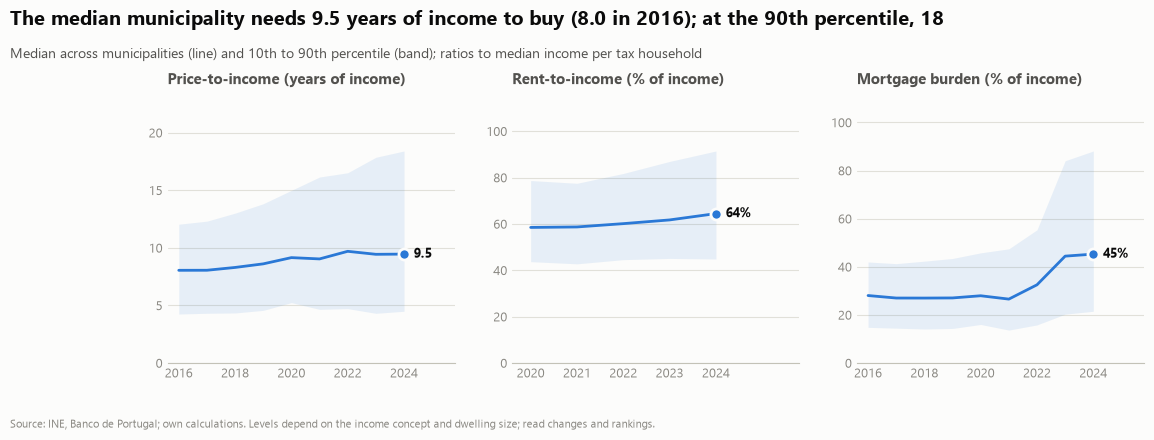

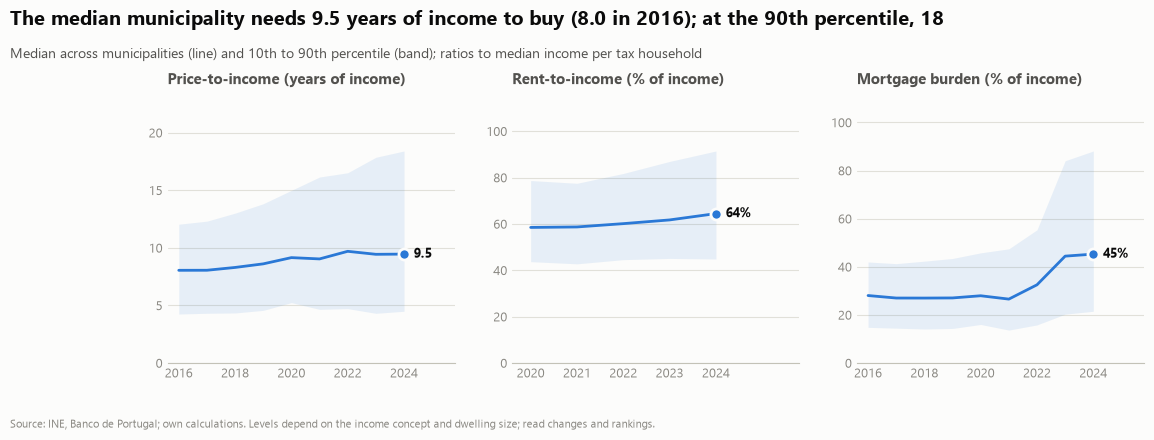

In [2]:
fans = {
    "pti": desc.yearly_quantiles(panel, "pti_years"),
    "rti": desc.yearly_quantiles(panel, "rti_pct"),
    "burden": desc.yearly_quantiles(panel, "mortgage_burden_pct"),
}
fig = charts.indicator_trends(
    [
        {"title": "Price-to-income (years of income)", "fan": fans["pti"], "unit_fmt": "{:.1f}"},
        {
            "title": "Rent-to-income (% of income)",
            "fan": fans["rti"],
            "unit_fmt": "{:.0f}%",
            "step": 1,
        },
        {"title": "Mortgage burden (% of income)", "fan": fans["burden"], "unit_fmt": "{:.0f}%"},
    ]
)
style.save_fig(fig, "p1", "affordability_indicators_trends")
fig

## Rates or prices? The mortgage burden with the rate held fixed
Same prices, incomes, dwelling sizes and loan terms as observed, but the mortgage rate stays at its 2016 level.

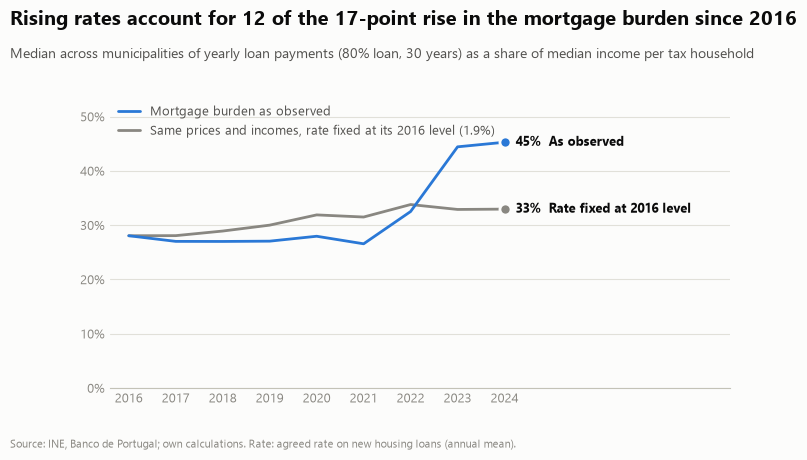

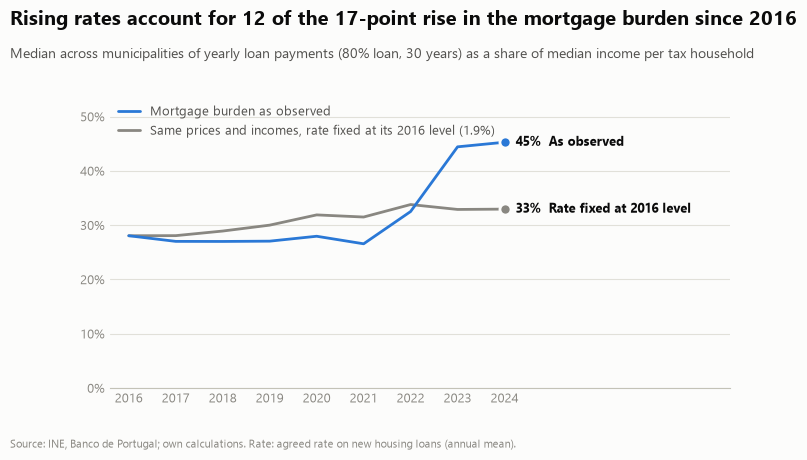

In [3]:
panel["burden_fixed_rate"] = desc.burden_at_fixed_rate(panel, 2016)
medians = panel.groupby("year")[["mortgage_burden_pct", "burden_fixed_rate"]].median().dropna()
rates = panel.drop_duplicates("year").set_index("year")["mortgage_rate_new_lt1y_pct"]
fig = charts.burden_rate_effect(
    medians["mortgage_burden_pct"], medians["burden_fixed_rate"], 2016, rates
)
style.save_fig(fig, "p1", "mortgage_burden_rate_effect")
fig

## The least affordable municipalities
Price-to-income in 2016 and 2024 for the 15 municipalities with the highest ratio in 2024.

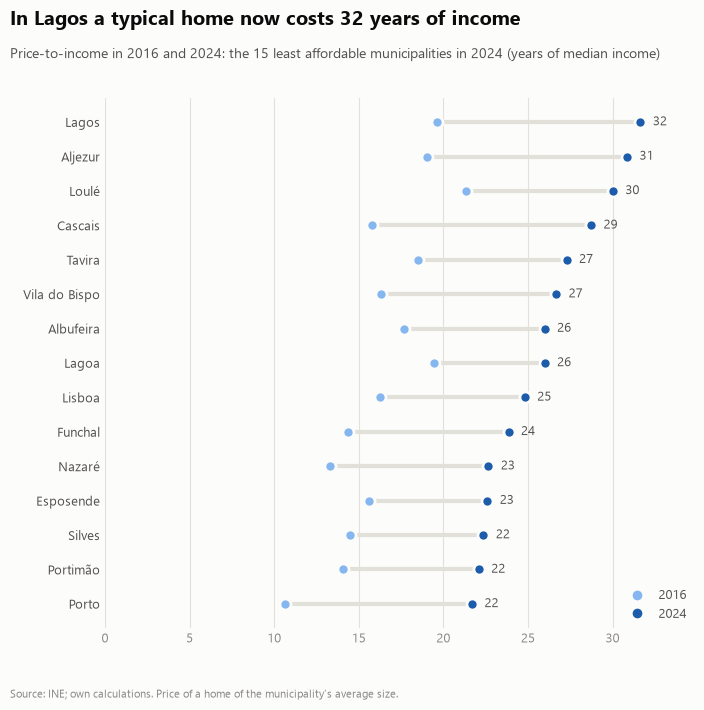

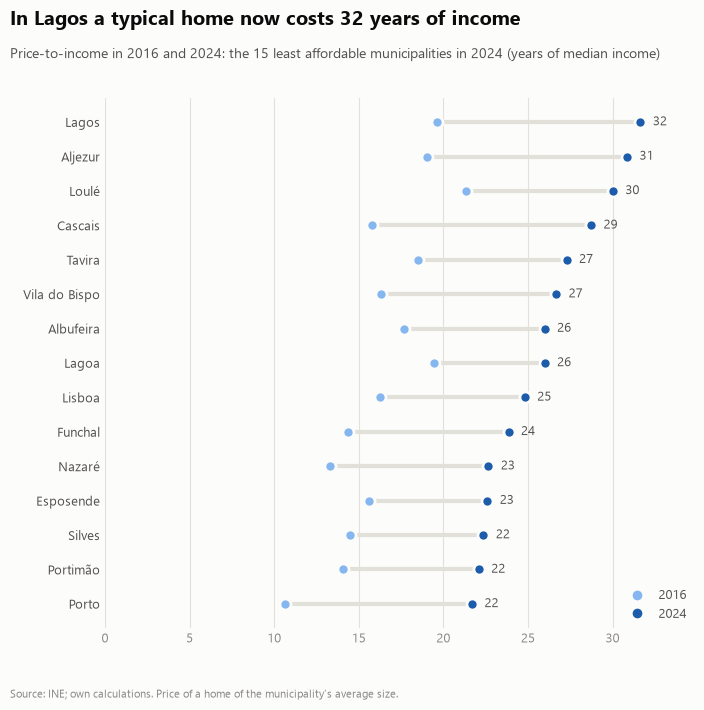

In [4]:
top = desc.top_with_baseline(panel, "pti_years", 2016, 2024, n=15)
fig = charts.pti_dumbbell(top, 2016, 2024)
style.save_fig(fig, "p1", "pti_least_affordable_2016_2024")
fig

## Maps, 2024
Hatched municipalities have no published price (or, for rents, fewer than 33 new leases).

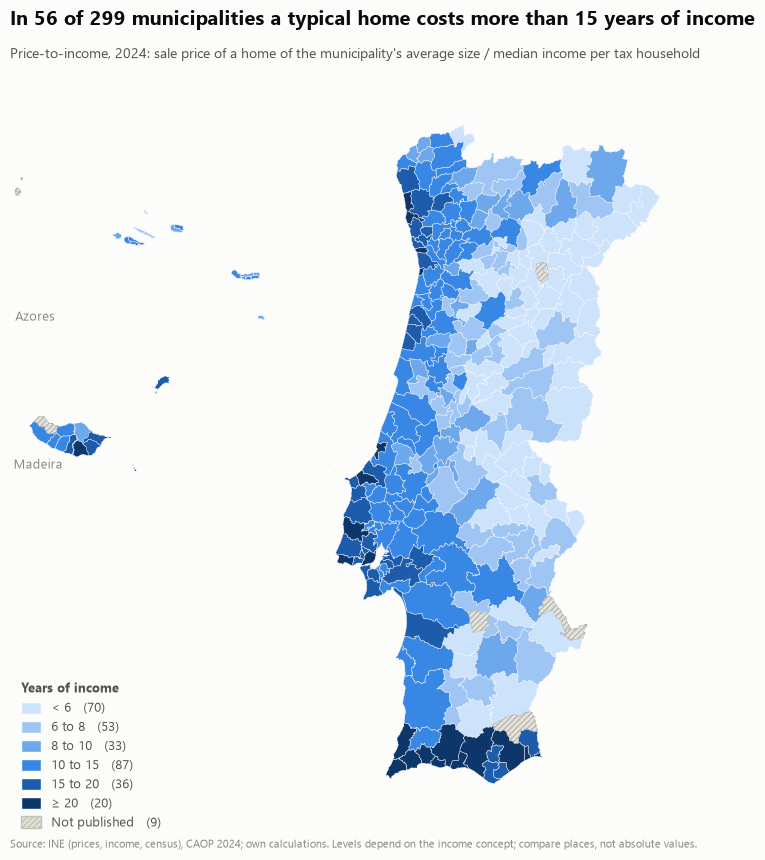

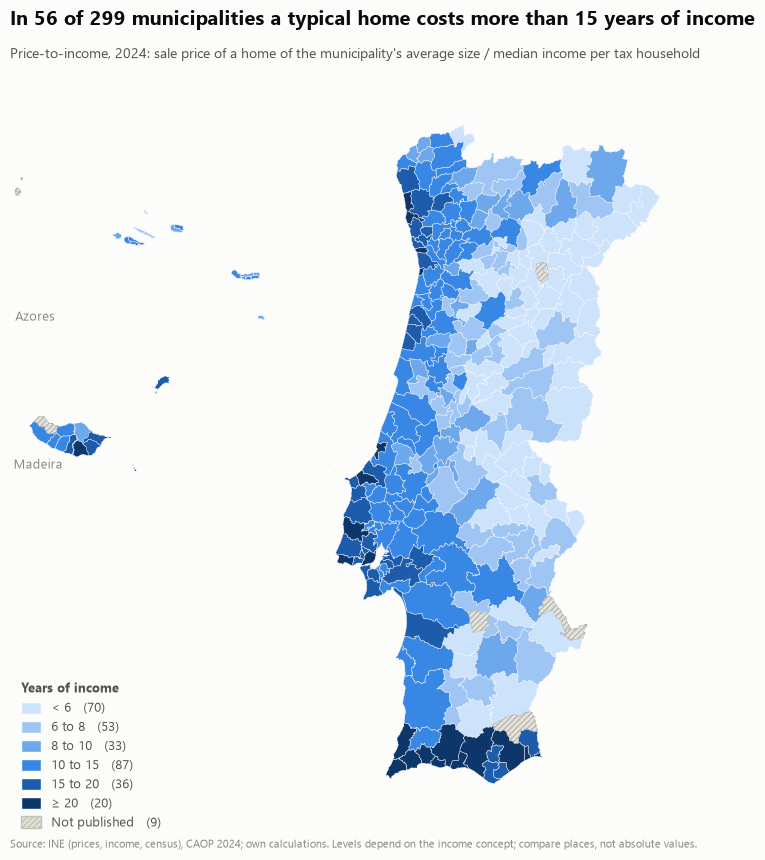

In [5]:
n = int(y24["pti_years"].notna().sum())
n15 = int((y24["pti_years"] > 15).sum())
fig = maps.choropleth(
    y24["pti_years"], geometry, [6, 8, 10, 15, 20], style.SEQUENTIAL_6,
    f"In {n15} of {n} municipalities a typical home costs more than 15 years of income",
    "Price-to-income, 2024: sale price of a home of the municipality's average size / median income per tax household",
    "Source: INE (prices, income, census), CAOP 2024; own calculations. Levels depend on the income concept; compare places, not absolute values.",
    "Years of income",
)  # fmt: skip
style.save_fig(fig, "p1", "pti_map_2024")
fig

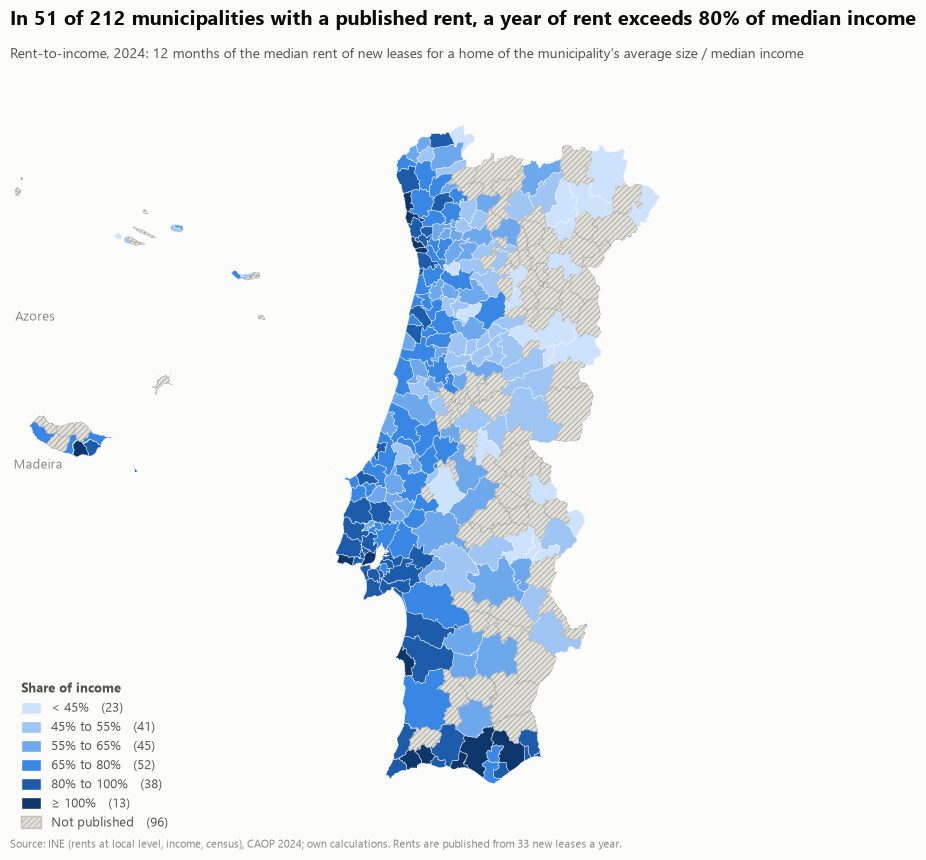

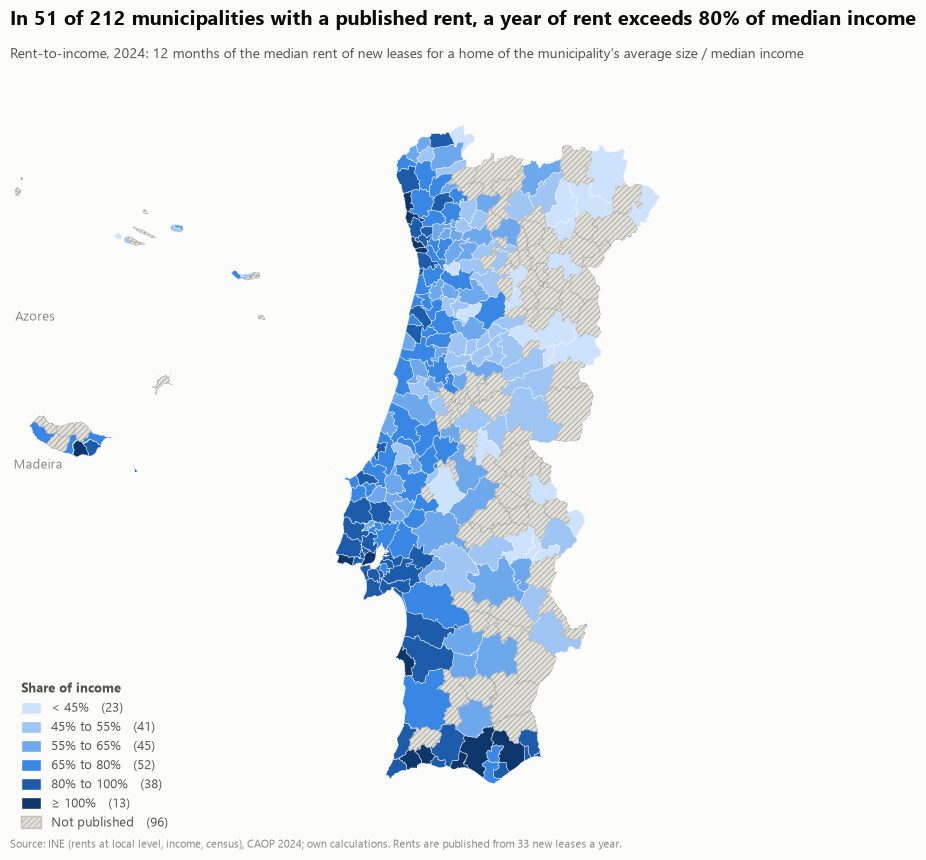

In [6]:
n = int(y24["rti_pct"].notna().sum())
n80 = int((y24["rti_pct"] > 80).sum())
fig = maps.choropleth(
    y24["rti_pct"], geometry, [45, 55, 65, 80, 100], style.SEQUENTIAL_6,
    f"In {n80} of {n} municipalities with a published rent, a year of rent exceeds 80% of median income",
    "Rent-to-income, 2024: 12 months of the median rent of new leases for a home of the municipality's average size / median income",
    "Source: INE (rents at local level, income, census), CAOP 2024; own calculations. Rents are published from 33 new leases a year.",
    "Share of income", fmt="{:g}", suffix="%",
)  # fmt: skip
style.save_fig(fig, "p1", "rti_map_2024")
fig

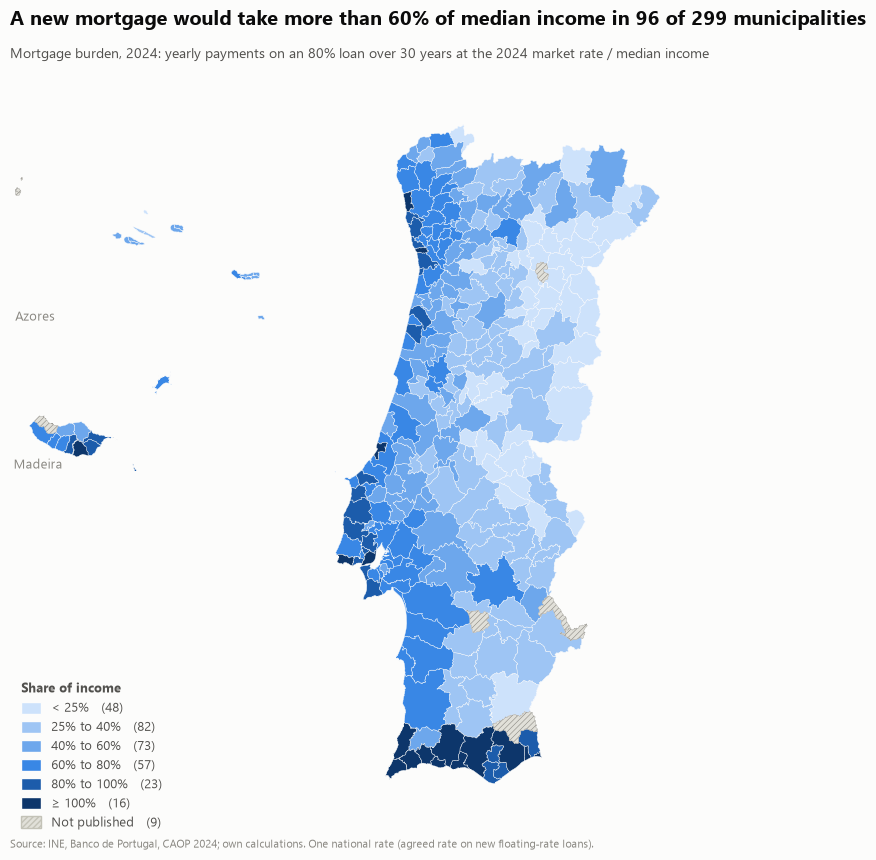

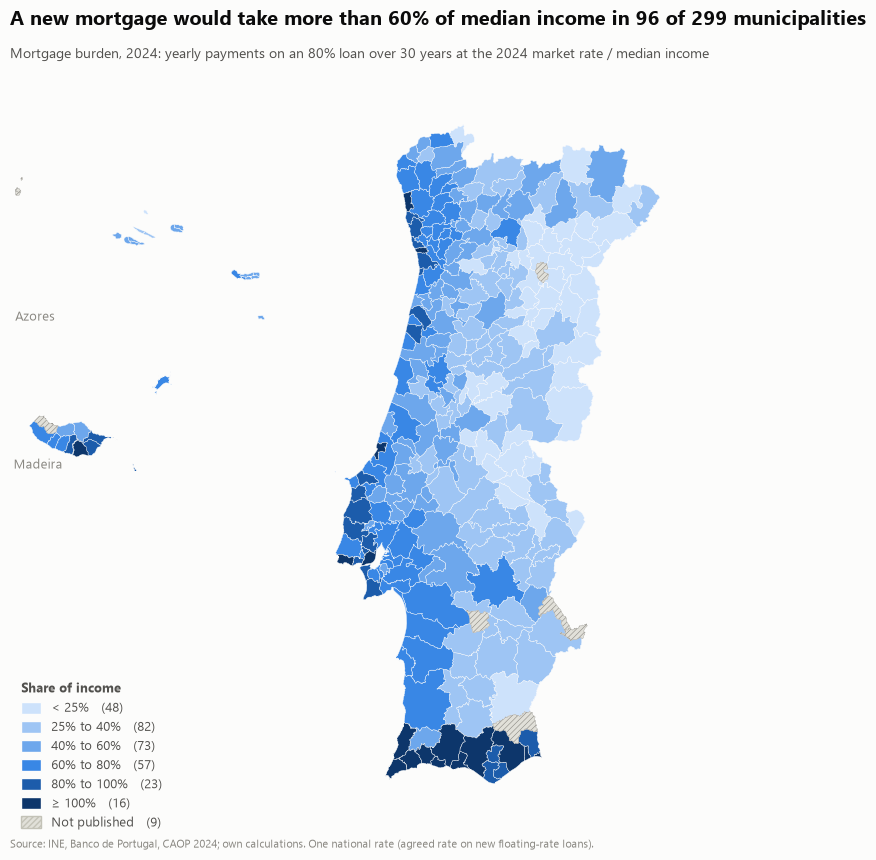

In [7]:
n = int(y24["mortgage_burden_pct"].notna().sum())
n60 = int((y24["mortgage_burden_pct"] > 60).sum())
fig = maps.choropleth(
    y24["mortgage_burden_pct"], geometry, [25, 40, 60, 80, 100], style.SEQUENTIAL_6,
    f"A new mortgage would take more than 60% of median income in {n60} of {n} municipalities",
    "Mortgage burden, 2024: yearly payments on an 80% loan over 30 years at the 2024 market rate / median income",
    "Source: INE, Banco de Portugal, CAOP 2024; own calculations. One national rate (agreed rate on new floating-rate loans).",
    "Share of income", fmt="{:g}", suffix="%",
)  # fmt: skip
style.save_fig(fig, "p1", "mortgage_burden_map_2024")
fig

## Where did price-to-income worsen? (RQ4.2)
Change in years of income between 2016 and 2024. Blue: more affordable (prices rose less than incomes).

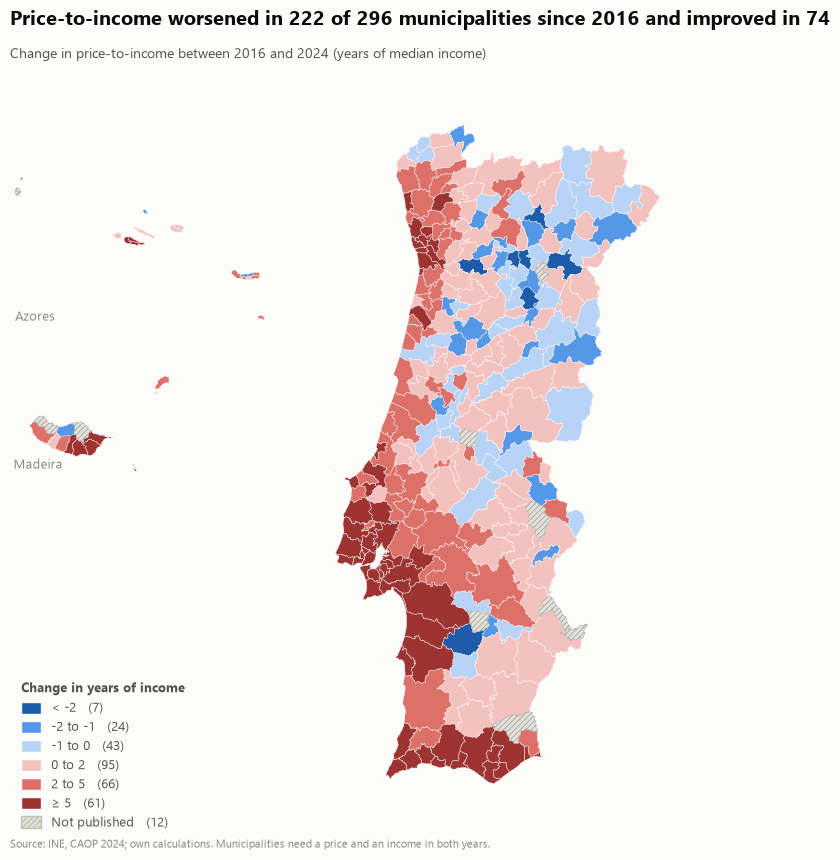

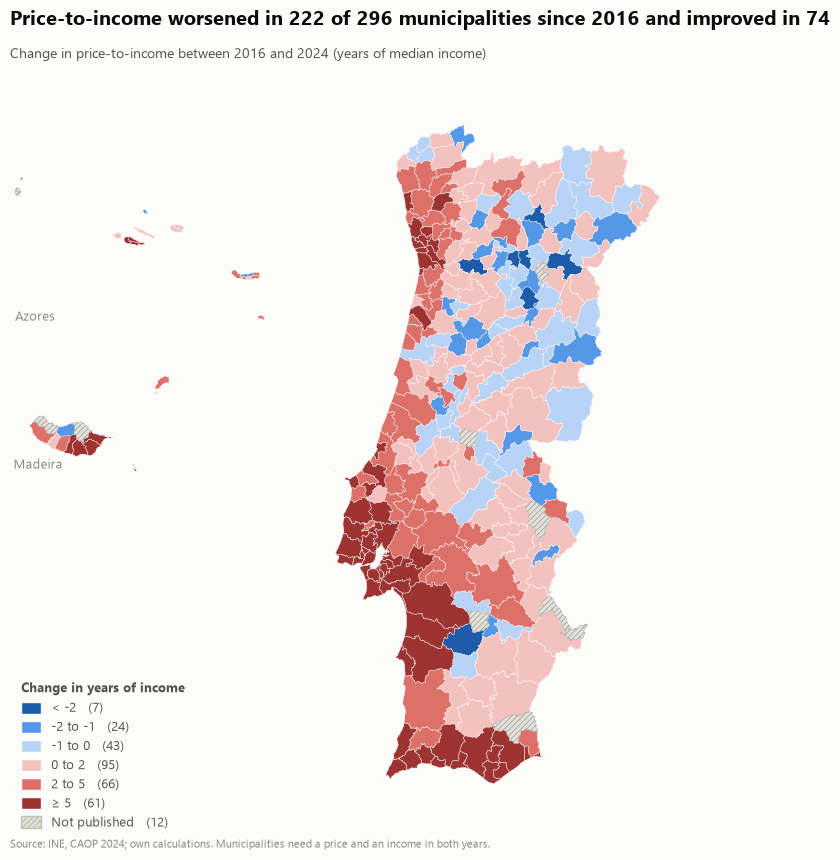

In [8]:
pti_change = desc.change(panel, "pti_years", 2016, 2024)
valid = pti_change.dropna()
worse, better = int((valid > 0).sum()), int((valid < 0).sum())
fig = maps.choropleth(
    pti_change, geometry, [-2, -1, 0, 2, 5], style.diverging_ramp(3),
    f"Price-to-income worsened in {worse} of {len(valid)} municipalities since 2016 and improved in {better}",
    "Change in price-to-income between 2016 and 2024 (years of median income)",
    "Source: INE, CAOP 2024; own calculations. Municipalities need a price and an income in both years.",
    "Change in years of income",
)  # fmt: skip
style.save_fig(fig, "p1", "pti_change_map_2016_2024")
fig

## Tables: municipalities and districts (RQ1.5, RQ4.2)

In [9]:
names = panel.drop_duplicates("muni_code").set_index("muni_code")[
    ["muni_name", "district", "territory"]
]
cols = [
    "pti_years",
    "pti_years_100sqm",
    "rti_pct",
    "mortgage_burden_pct",
    "price_sqm_eur",
    "rent_sqm_eur",
    "income_median_eur",
    "dwelling_area_sqm",
]
ranking = names.join(y24[cols]).round(2)
ranking["pti_rank"] = ranking["pti_years"].rank(ascending=False, method="min")
ranking = ranking.reset_index().sort_values("pti_rank")
style.save_table(ranking, "p1", "affordability_by_municipality_2024")
ranking.head(10)[["muni_name", "district", "pti_years", "rti_pct", "mortgage_burden_pct"]]

,muni_name,district,pti_years,rti_pct,mortgage_burden_pct
107,Lagos,Faro,31.65,111.23,151.50
103,Aljezur,Faro,30.86,91.51,147.72
108,Loulé,Faro,30.02,116.84,143.71
151,Cascais,Lisboa,28.73,130.23,137.53
114,Tavira,Faro,27.28,110.29,130.61
115,Vila do Bispo,Faro,26.67,84.70,127.66
101,Albufeira,Faro,25.99,109.32,124.40
106,Lagoa,Faro,25.99,98.79,124.40
152,Lisboa,Lisboa,24.81,109.30,118.79
280,Funchal,Ilha da Madeira,23.85,107.62,114.18


In [10]:
districts = desc.district_summary(panel, "pti_years", 2016, 2024).round(2)
style.save_table(districts, "p1", "pti_by_district_2016_2024")
districts

,district,median_2016,median_2024,municipalities_n,change
0,Faro,16.30,22.37,15,6.07
1,Lisboa,9.70,16.45,16,6.75
2,Ilha da Madeira,11.94,16.23,8,4.29
3,Ilha de Porto Santo,12.51,15.59,1,3.08
4,Setúbal,8.36,15.51,13,7.16
5,Porto,10.34,14.19,18,3.85
6,Braga,9.97,12.51,14,2.53
7,Ilha de São Miguel,10.35,12.42,6,2.07
8,Aveiro,10.04,11.95,19,1.91
9,Leiria,8.58,10.92,16,2.34


In [11]:
change_table = names.join(pti_change.rename("pti_change_2016_2024")).dropna().round(2).reset_index()
style.save_table(
    change_table.sort_values("pti_change_2016_2024", ascending=False),
    "p1",
    "pti_change_by_municipality_2016_2024",
)
change_table.nlargest(10, "pti_change_2016_2024")[["muni_name", "district", "pti_change_2016_2024"]]

,muni_name,district,pti_change_2016_2024
146,Cascais,Lisboa,12.95
102,Lagos,Faro,12.03
98,Aljezur,Faro,11.82
183,Porto,Porto,11.04
110,Vila do Bispo,Faro,10.37
6,Espinho,Aveiro,10.00
273,Funchal,Ilha da Madeira,9.51
157,Odivelas,Lisboa,9.47
136,Nazaré,Leiria,9.36
151,Oeiras,Lisboa,8.84


## Key numbers

In [12]:
q = fans["pti"]
print(
    f"PTI median {q['q50'].iloc[0]:.2f} ({q.index[0]}) -> {q['q50'].iloc[-1]:.2f} ({q.index[-1]}); p90 {q['q90'].iloc[0]:.1f} -> {q['q90'].iloc[-1]:.1f}"
)
share15 = desc.share_above(panel, "pti_years", 15)
print(
    f"Share of municipalities with PTI > 15: {100 * share15['share'].iloc[0]:.0f}% ({share15.index[0]}) -> {100 * share15['share'].iloc[-1]:.0f}% ({share15.index[-1]})"
)
b = medians
print(
    f"Median burden {b['mortgage_burden_pct'].iloc[0]:.1f}% -> {b['mortgage_burden_pct'].iloc[-1]:.1f}%; with the 2016 rate fixed: {b['burden_fixed_rate'].iloc[-1]:.1f}%"
)
print(
    f"Largest PTI: {ranking.iloc[0]['muni_name']} {ranking.iloc[0]['pti_years']:.1f}; smallest: {ranking.dropna(subset=['pti_years']).iloc[-1]['muni_name']} {ranking.dropna(subset=['pti_years']).iloc[-1]['pti_years']:.1f}"
)
print(f"PTI improved in {better} municipalities, worsened in {worse} (of {len(valid)})")

PTI median 8.05 (2016) -> 9.46 (2024); p90 12.1 -> 18.4
Share of municipalities with PTI > 15: 5% (2016) -> 19% (2024)
Median burden 28.0% -> 45.3%; with the 2016 rate fixed: 32.9%
Largest PTI: Lagos 31.6; smallest: Armamar 2.4
PTI improved in 74 municipalities, worsened in 222 (of 296)
